# HDBSCAN parameter selection for starling syllable clustering (Supp. Fig. S1)

Draws the five panels of Supplementary Figure S1: how the number of syllable clusters and the share of unclustered syllables depend on `min_cluster_size`, and how stable both are when each bird's syllables are subsampled.

Reads one file, `clustering_validation_data.pkl`, written by Cells C1 to C3 of the data notebook. All clustering is done there; this notebook only plots.

In [1]:
# Cell 1: paths and figure style
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# Paths relative to the repository, so a fresh clone runs without edits (from the repo folder or
# from notebooks/). To use other copies, e.g. on the cluster: export HELIOX_DATA_DIR=/path/to/data/derived
REPO = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.environ.get('HELIOX_DATA_DIR', os.path.join(REPO, 'data'))
FIG_DIR = os.environ.get('HELIOX_FIG_DIR', os.path.join(REPO, 'figures'))
DATA_PATH = os.path.join(DATA_DIR, 'clustering_validation_data.pkl')
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({'font.size': 15, 'axes.titlesize': 18, 'axes.labelsize': 16, 'xtick.labelsize': 14,
                     'ytick.labelsize': 14, 'legend.fontsize': 13, 'legend.title_fontsize': 14,
                     'savefig.dpi': 300, 'savefig.bbox': 'tight'})


def save(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(os.path.join(FIG_DIR, f'{name}.{ext}'))
    print('saved', os.path.join(FIG_DIR, name + '.png'))

In [2]:
# Cell 2: load
data = pd.read_pickle(DATA_PATH)
sweep, subsampling = data['sweep'], data['subsampling']
CHOSEN = data['meta']['settings']['CHOSEN_PERCENT']      # the threshold used in the paper (0.5%)
print('made', data['meta']['created'])
print(f'{sweep["bird"].nunique()} birds; {len(sweep)} threshold runs; {len(subsampling)} subsample runs')

made 2026-10-11T12:14:41
6 birds; 48 threshold runs; 1775 subsample runs


In [3]:
# Cell 3: the panels
def panel_letter(ax, letter):
    ax.text(-0.09, 1.04, letter, transform=ax.transAxes, fontsize=24, fontweight='bold', va='bottom', ha='right')


def percent_axis(ax, percents):
    ax.set_xscale('log')
    ax.set_xticks(percents)
    ax.set_xticklabels([f'{p:.1f}%' if p < 1 else f'{int(p)}%' for p in percents])
    ax.minorticks_off()


def panel_subsampling(ax, value, ylabel, scale=1.0, legend=False):
    """A, B: the draws of a bird are averaged first, then the line is the mean across birds and the
    band runs from the lowest to the highest bird."""
    per_bird = subsampling.groupby(['mcs_frac', 'bird', 'sample_frac'], as_index=False)[value].mean()
    across = per_bird.groupby(['mcs_frac', 'sample_frac'])[value].agg(['mean', 'min', 'max']).reset_index()
    for frac, d in across.groupby('mcs_frac'):
        x = d['sample_frac'] * 100
        line, = ax.plot(x, d['mean'] * scale, marker='o', markersize=8, linewidth=2.2, label=f'{frac * 100:.2f}%')
        ax.fill_between(x, d['min'] * scale, d['max'] * scale, color=line.get_color(), alpha=0.15, linewidth=0)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    if legend:
        ax.legend(title='min_cluster_size', ncol=3, loc='upper right')


def panel_sweep_mean(ax):
    """C: mean across birds at each threshold, band from the lowest to the highest bird."""
    g = sweep.groupby('percent')['n_clusters'].agg(['mean', 'min', 'max']).reset_index()
    ax.fill_between(g['percent'], g['min'], g['max'], color='#9E9E9E', alpha=0.28, linewidth=0)
    ax.plot(g['percent'], g['mean'], color='black', linestyle='--', linewidth=3.5, marker='o', markersize=8)
    for x, y in zip(g['percent'], g['mean']):
        ax.annotate(f'{y:.0f}', (x, y), textcoords='offset points', xytext=(0, 22), ha='center', fontsize=15, color='#333333')
    percent_axis(ax, list(g['percent']))
    ax.set_ylim(top=max(ax.get_ylim()[1], g['max'].max() * 1.05))
    ax.set_xlabel('Minimum Percent of Total Data in Each Syllable Cluster')
    ax.set_ylabel('Identified Syllable Clusters')
    ax.grid(True, which='major', alpha=0.2)


def panel_sweep_birds(ax):
    """D: the same sweep, one line per bird."""
    for bird, d in sweep.groupby('bird'):
        ax.plot(d['percent'], d['n_clusters'], marker='o', markersize=5, linewidth=2,
                label=f'{bird} (N={int(d["n_syllables"].iloc[0])})')
    ax.axvline(CHOSEN, color='#D55E00', linestyle=':', linewidth=2, zorder=0)
    percent_axis(ax, sorted(sweep['percent'].unique()))
    ax.set_xlabel('Minimum Percent of Total Data in Each Syllable Cluster')
    ax.set_ylabel('Identified Syllable Clusters')
    ax.grid(True, which='major', alpha=0.2)
    ax.legend(title='Bird ID', frameon=False, fontsize=13)


def panel_noise(ax):
    """E: unclustered share per bird at the chosen threshold, with the number of clusters on each bar."""
    d = sweep[np.isclose(sweep['percent'], CHOSEN)].sort_values('bird')
    x = np.arange(len(d))
    ax.bar(x, d['noise_frac'] * 100, color='#7F7F7F', alpha=0.85)
    for xi, k in zip(x, d['n_clusters']):
        ax.annotate(f'{int(k)}', (xi, 1), textcoords='offset points', xytext=(0, 3), ha='center', fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([b.replace('s_b', '') for b in d['bird']], rotation=45, ha='right')
    ax.set_ylabel('Noise (% of syllables)')
    ax.set_xlabel(f'Bird (cluster count labeled, at {CHOSEN}%)')
    ax.grid(True, axis='y', alpha=0.2)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)

saved /mnt/cube/lstanwic/umap_avgn_shared/lauren_umap/heliox_processing/notebooks/for_github/figures/figS1_clustering_validation.png


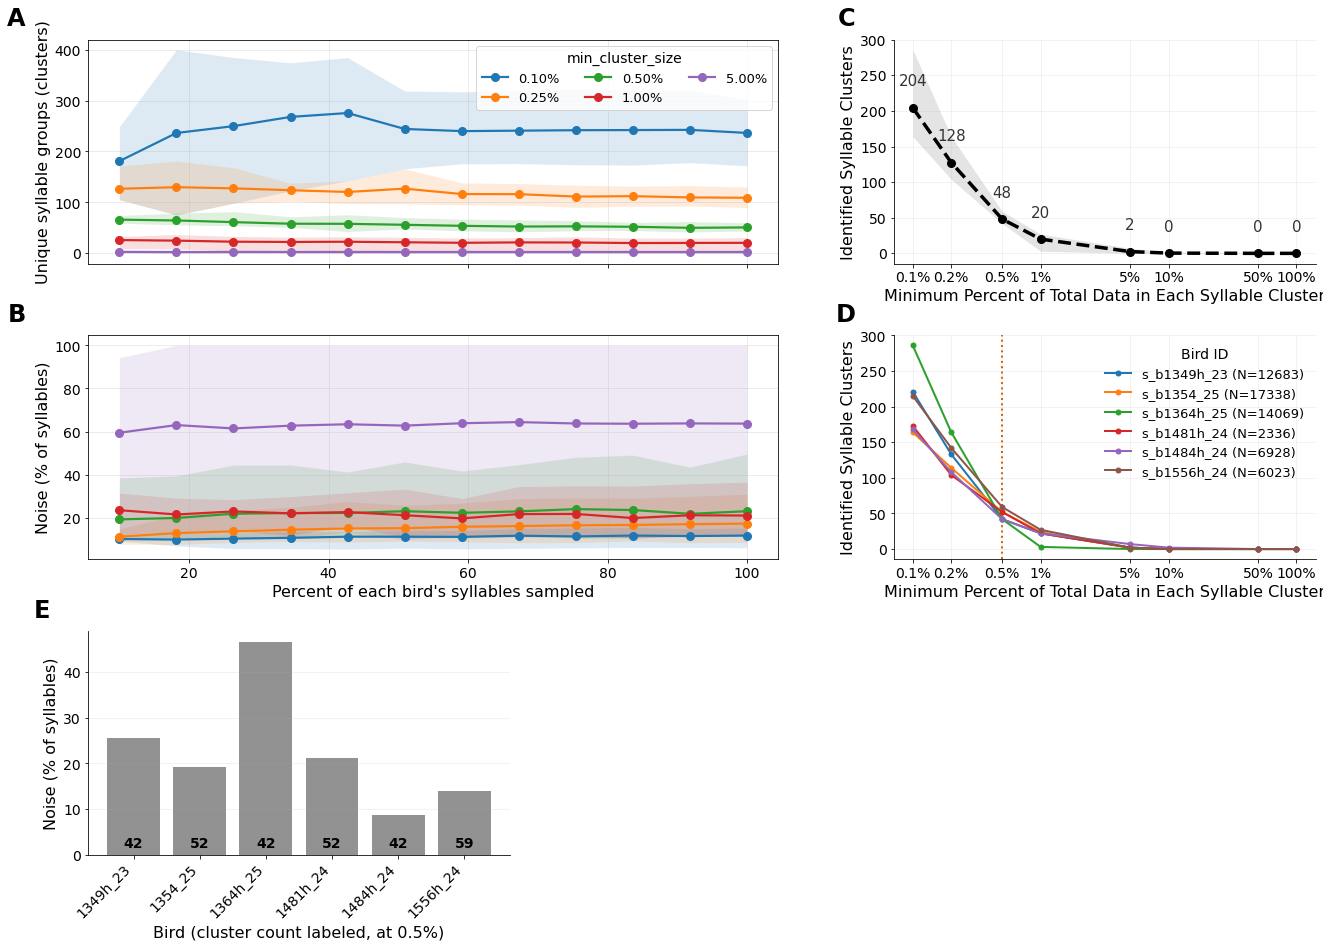

In [4]:
# Cell 4: Supp. Fig. S1
fig = plt.figure(figsize=(22, 15))
grid = GridSpec(3, 5, figure=fig, hspace=0.32, wspace=0.75)
ax_a = fig.add_subplot(grid[0, :3])
ax_b = fig.add_subplot(grid[1, :3], sharex=ax_a)
ax_c = fig.add_subplot(grid[0, 3:])
ax_d = fig.add_subplot(grid[1, 3:])
ax_e = fig.add_subplot(grid[2, :2])

panel_subsampling(ax_a, 'n_clusters', 'Unique syllable groups (clusters)', legend=True)
panel_subsampling(ax_b, 'noise_frac', 'Noise (% of syllables)', scale=100)
plt.setp(ax_a.get_xticklabels(), visible=False)
ax_b.set_xlabel("Percent of each bird's syllables sampled")
panel_sweep_mean(ax_c)
panel_sweep_birds(ax_d)
panel_noise(ax_e)
for ax, letter in zip([ax_a, ax_b, ax_c, ax_d, ax_e], 'ABCDE'):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(ax in (ax_a, ax_b))      # A and B keep their frame, as published
    panel_letter(ax, letter)

save(fig, 'figS1_clustering_validation')
plt.show()

In [5]:
# Cell 5: the numbers in this figure against the numbers printed in V130
# Panel C annotations, panel D legend (syllables per bird), panel E bar labels, and the legend text.
PAPER_MEAN_CLUSTERS = {0.1: 204, 0.2: 128, 0.5: 48, 1: 20, 5: 2, 10: 0, 50: 0, 100: 0}
PAPER_BIRDS = pd.DataFrame({'syllables': [12683, 17338, 14069, 2336, 6928, 6023], 'clusters': [42, 52, 42, 52, 42, 59]},
                           index=['s_b1349h_23', 's_b1354_25', 's_b1364h_25', 's_b1481h_24', 's_b1484h_24', 's_b1556h_24'])
PAPER_HIGH_NOISE_BIRD, PAPER_HIGH_NOISE = 's_b1364h_25', 47      # 'substantially elevated noise (~47%)'
PAPER_NOISE_CEILING = 25                                         # 'Five birds show ... moderate noise (<=25%)'


def flag(same):
    return '' if same else '[CHECK]'


mean_here = sweep.groupby('percent')['n_clusters'].mean()
c = pd.DataFrame({'here': [f'{mean_here.get(p, np.nan):.0f}' for p in PAPER_MEAN_CLUSTERS],
                  'V130': [str(v) for v in PAPER_MEAN_CLUSTERS.values()]}, index=[f'{p}%' for p in PAPER_MEAN_CLUSTERS])
c[''] = [flag(a == b) for a, b in zip(c['here'], c['V130'])]
print('Panel C, mean clusters across birds at each threshold:')
print(c.T.to_string())

at = sweep[np.isclose(sweep['percent'], CHOSEN)].set_index('bird')
b = pd.DataFrame({'syllables': at['n_syllables'], 'V130 ': PAPER_BIRDS['syllables'],
                  'clusters': at['n_clusters'], 'V130': PAPER_BIRDS['clusters'], 'noise_%': (at['noise_frac'] * 100).round(1)})
b[''] = [flag(r['syllables'] == r['V130 '] and r['clusters'] == r['V130']) for _, r in b.iterrows()]
print(f'\nPanels D and E, per bird at {CHOSEN}%:')
print(b.to_string())

noise = at['noise_frac'] * 100
#others = noise.drop(PAPER_HIGH_NOISE_BIRD, errors='ignore')


Panel C, mean clusters across birds at each threshold:
     0.1% 0.2% 0.5%  1% 5% 10% 50% 100%
here  204  128   48  20  2   0   0    0
V130  204  128   48  20  2   0   0    0
                                       

Panels D and E, per bird at 0.5%:
             syllables  V130   clusters  V130  noise_%  
s_b1349h_23      12683  12683        42    42     25.6  
s_b1354_25       17338  17338        52    52     19.3  
s_b1364h_25      14069  14069        42    42     46.6  
s_b1481h_24       2336   2336        52    52     21.2  
s_b1484h_24       6928   6928        42    42      8.7  
s_b1556h_24       6023   6023        59    59     14.0  
